<center><img src='https://media.licdn.com/dms/image/D5612AQEFNAog5YvQGA/article-cover_image-shrink_720_1280/0/1701862732849?e=1720051200&v=beta&t=5uNFKqQTfWt0CSUKxvAPOUDKviP1B1YyBmoL22VduDQ' width="768"></center>

<h1><center>[How to] Inference MLLM(Multimodal LLM) - LLaVA-Phi3 </center><h1>

# About this notebook
- MLLM (Multimoda LLM) inference starter code
  (Base is LLaVA + Phi3 [here](https://github.com/mbzuai-oryx/LLaVA-pp/).)
- Describing images (It is also possible to predict audio by replacing the vision tower, but we are only dealing with images here.)
- Visual Understanding (e.g. bbox)


I want to show how to use `MLLM (Multimoda LLM)` inference in kaggle nodebook.



If this notebook is helpful, feel free to upvote :)

And please upvote the original notebook and discussion as well.

`V1` - Run test and add bbox
- LLM: Phi3 (LLaVA 7B is failed due to GPU OOM)

Please see,
- https://llava-vl.github.io/
- https://www.reddit.com/r/ChatGPT/comments/1cb16cg/microsoft_introduces_phi3_llm_that_runs_on_the/?rdt=57581
- https://github.com/mbzuai-oryx/LLaVA-pp

<img src='https://llava-vl.github.io/images/llava_arch.png' width="768">
<img src='https://llava-vl.github.io/images/cmp_ironing.png' width="768">

# Install

In [1]:
!git clone https://github.com/mbzuai-oryx/LLaVA-pp.git

Cloning into 'LLaVA-pp'...
remote: Enumerating objects: 71, done.
remote: Counting objects: 100% (71/71), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 71 (delta 31), reused 60 (delta 20), pack-reused 0
Unpacking objects: 100% (71/71), 6.47 MiB | 9.39 MiB/s, done.


In [2]:
cd LLaVA-pp

/kaggle/working/LLaVA-pp


In [3]:
!git submodule update --init --recursive

Submodule 'LLaVA' (https://github.com/haotian-liu/LLaVA) registered for path 'LLaVA'
Cloning into '/kaggle/working/LLaVA-pp/LLaVA'...
Submodule path 'LLaVA': checked out '3e337ad269da3245643a2724a1d694b5839c37f9'


In [4]:
ls

LLaMA-3-V/  LLaVA/  Phi-3-V/  README.md  images/  scripts/


In [5]:
!cp Phi-3-V/train.py LLaVA/llava/train/train.py
!cp Phi-3-V/llava_phi3.py LLaVA/llava/model/language_model/llava_phi3.py
!cp Phi-3-V/builder.py LLaVA/llava/model/builder.py
!cp Phi-3-V/model__init__.py LLaVA/llava/model/__init__.py
!cp Phi-3-V/main__init__.py LLaVA/llava/__init__.py
!cp Phi-3-V/conversation.py LLaVA/llava/conversation.py

In [6]:
%cd LLaVA
!pip install --upgrade pip  > /dev/null
!pip install -e .  > /dev/null
!pip install git+https://github.com/huggingface/transformers@a98c41798cf6ed99e1ff17e3792d6e06a2ff2ff3  > /dev/null

!export PYTHONPATH="./:$PYTHONPATH"

/kaggle/working/LLaVA-pp/LLaVA
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jupyterlab 4.1.6 requires httpx>=0.25.0, but you have httpx 0.24.0 which is incompatible.
jupyterlab 4.1.6 requires jupyter-lsp>=2.0.0, but you have jupyter-lsp 1.5.1 which is incompatible.
jupyterlab-lsp 5.1.0 requires jupyter-lsp>=2.0.0, but you have jupyter-lsp 1.5.1 which is incompatible.
  Running command git clone --filter=blob:none --quiet https://github.com/huggingface/transformers /tmp/pip-req-build-fptdp8d7
  Running command git rev-parse -q --verify 'sha^a98c41798cf6ed99e1ff17e3792d6e06a2ff2ff3'
  Running command git fetch -q https://github.com/huggingface/transformers a98c41798cf6ed99e1ff17e3792d6e06a2ff2ff3
  Running command git checkout -q a98c41798cf6ed99e1ff17e3792d6e06a2ff2ff3
ERROR: pip's dependency resolver does not currently take into account all the packages that

# Import required packages

In [7]:
import torch
from llava.constants import IMAGE_TOKEN_INDEX, DEFAULT_IMAGE_TOKEN, DEFAULT_IM_START_TOKEN, DEFAULT_IM_END_TOKEN, IMAGE_PLACEHOLDER
from llava.conversation import conv_templates
from llava.model.builder import load_pretrained_model
from llava.utils import disable_torch_init
from llava.mm_utils import process_images, tokenizer_image_token, get_model_name_from_path
import requests
from PIL import Image
from io import BytesIO
import re
from llava.utils import disable_torch_init

2024-04-30 16:01:22.949341: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-30 16:01:22.949454: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-30 16:01:23.076409: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Define helper functions

In [8]:
def image_parser(args):
    out = args.image_file.split(args.sep)
    return out


def load_image(image_file):
    if image_file.startswith("http") or image_file.startswith("https"):
        response = requests.get(image_file)
        image = Image.open(BytesIO(response.content)).convert("RGB")
    else:
        image = Image.open(image_file).convert("RGB")
    return image


def load_images(image_files):
    out = []
    for image_file in image_files:
        image = load_image(image_file)
        out.append(image)
    return out

# Load LLaVA-Phi3

In [9]:
disable_torch_init()

model_path = "/kaggle/input/llava-phi-3-mini-4k-instruct/transformers/1.0.0/1/llava-phi-3-mini-4k-instruct"
model_name = get_model_name_from_path(model_path)
tokenizer, model, image_processor, context_len = load_pretrained_model(model_path, None, model_name)

Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


config.json:   0%|          | 0.00/4.76k [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Some weights of the model checkpoint at /kaggle/input/llava-phi-3-mini-4k-instruct/transformers/1.0.0/1/llava-phi-3-mini-4k-instruct were not used when initializing LlavaPhiForCausalLM: ['model.vision_tower.vision_tower.vision_model.embeddings.class_embedding', 'model.vision_tower.vision_tower.vision_model.embeddings.patch_embedding.weight', 'model.vision_tower.vision_tower.vision_model.embeddings.position_embedding.weight', 'model.vision_tower.vision_tower.vision_model.encoder.layers.0.layer_norm1.bias', 'model.vision_tower.vision_tower.vision_model.encoder.layers.0.layer_norm1.weight', 'model.vision_tower.vision_tower.vision_model.encoder.layers.0.layer_norm2.bias', 'model.vision_tower.vision_tower.vision_model.encoder.layers.0.layer_norm2.weight', 'model.vision_tower.vision_tower.vision_model.encoder.layers.0.mlp.fc1.bias', 'model.vision_tower.vision_tower.vision_model.encoder.layers.0.mlp.fc1.weight', 'model.vision_tower.vision_tower.vision_model.encoder.layers.0.mlp.fc2.bias', 'mo

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

/opt/conda/lib/python3.10/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


## Create the prompt in Phi-3 Format

DEFAULT_IM_START_TOKEN
- \<im_start\>

DEFAULT_IMAGE_TOKEN
- \<image\>

DEFAULT_IM_END_TOKEN
- \<im_end\>

In [10]:
qs = "Please describe the plant traits in detail. Please think step by step."
 
conv_mode = "phi3_instruct"

image_token_se = DEFAULT_IM_START_TOKEN + DEFAULT_IMAGE_TOKEN + DEFAULT_IM_END_TOKEN
if IMAGE_PLACEHOLDER in qs:
    if model.config.mm_use_im_start_end:
        qs = re.sub(IMAGE_PLACEHOLDER, image_token_se, qs)
    else:
        qs = re.sub(IMAGE_PLACEHOLDER, DEFAULT_IMAGE_TOKEN, qs)
else:
    if model.config.mm_use_im_start_end:
        qs = image_token_se + "\n" + qs
    else:
        qs = DEFAULT_IMAGE_TOKEN + "\n" + qs

conv = conv_templates[conv_mode].copy()
conv.system = """<|system|>\nYou are a helpful visual AI assistant."""
conv.append_message(conv.roles[0], qs)
conv.append_message(conv.roles[1], None)
prompt = conv.get_prompt()

print(prompt)

<|system|>
You are a helpful visual AI assistant.<|end|>
<|user|>
<image>
Please describe the plant traits in detail. Please think step by step.<|end|>
<|assistant|>



# Inference for plant iamge - Describing plants

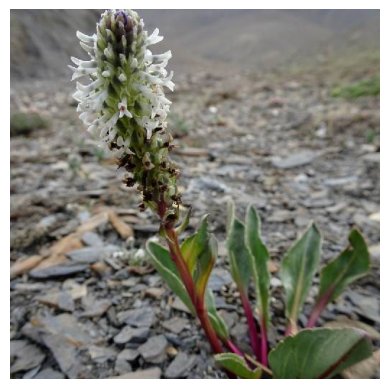

In [11]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

saple_img_path = '/kaggle/input/planttraits2024/train_images/100438030.jpeg'

img = mpimg.imread(saple_img_path)
plt.imshow(img)
plt.axis('off')
plt.show()

In [12]:
image_name = saple_img_path
image_files = [image_name]
images = load_images(image_files)
image_sizes = [x.size for x in images]
images_tensor = process_images(
    images,
    image_processor,
    model.config
).to(model.device, dtype=torch.float16)

input_ids = (
    tokenizer_image_token(prompt, tokenizer, IMAGE_TOKEN_INDEX, return_tensors="pt")
    .unsqueeze(0)
    .cuda()
)

In [13]:
temperature = 0.2
top_p = 0.7
num_beams = 1
max_new_tokens = 512

with torch.inference_mode():
    output_ids = model.generate(
        input_ids,
        images=images_tensor,
        image_sizes=image_sizes,
        do_sample=True if temperature > 0 else False,
        temperature=temperature,
        top_p=top_p,
        num_beams=num_beams,
        max_new_tokens=max_new_tokens,
        use_cache=True,
    )

outputs = tokenizer.batch_decode(output_ids, skip_special_tokens=True)[0].strip()
outputs = outputs.replace("<|end|>", "").strip()
#print(f"\n{outputs}\n")

You are not running the flash-attention implementation, expect numerical differences.


In [14]:
outputs

'The image features a small plant with a white flower growing in a rocky area. The flower is located at the top of the plant, and the plant itself is surrounded by rocks and dirt. The plant appears to be a wildflower, as it is growing in a natural environment without any human intervention. The white flower stands out against the rocky background, making it a visually striking element in the scene.'

# Inference other images

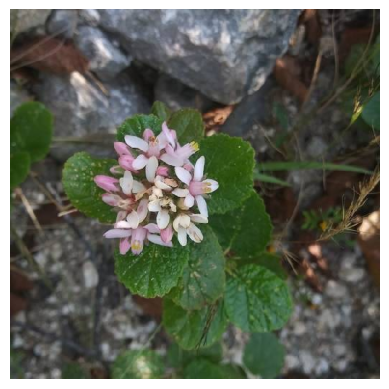

In [15]:
saple_img_path = '/kaggle/input/planttraits2024/train_images/100282707.jpeg'

img = mpimg.imread(saple_img_path)
plt.imshow(img)
plt.axis('off')
plt.show()

In [16]:
image_name = saple_img_path
image_files = [image_name]
images = load_images(image_files)
image_sizes = [x.size for x in images]
images_tensor = process_images(
    images,
    image_processor,
    model.config
).to(model.device, dtype=torch.float16)

input_ids = (
    tokenizer_image_token(prompt, tokenizer, IMAGE_TOKEN_INDEX, return_tensors="pt")
    .unsqueeze(0)
    .cuda()
)

In [17]:
temperature = 0.2
top_p = 0.7
num_beams = 1
max_new_tokens = 512

with torch.inference_mode():
    output_ids = model.generate(
        input_ids,
        images=images_tensor,
        image_sizes=image_sizes,
        do_sample=True if temperature > 0 else False,
        temperature=temperature,
        top_p=top_p,
        num_beams=num_beams,
        max_new_tokens=max_new_tokens,
        use_cache=True,
    )

outputs = tokenizer.batch_decode(output_ids, skip_special_tokens=True)[0].strip()
outputs = outputs.replace("<|end|>", "").strip()
#print(f"\n{outputs}\n")

In [18]:
outputs

"The image features a small, pink flower growing on a green plant. The flower is located in the center of the plant, surrounded by leaves. The leaves are green and spread out, covering the majority of the plant's surface. The pink flower stands out against the green leaves, creating a visually appealing contrast. The plant appears to be thriving in its natural environment, with the flower blooming and the leaves providing a healthy, vibrant appearance."

# Inference BBox for image

In [19]:
qs = "Please generate the bounding box for the flower. Bounding box output format is coco. Please think step by step."
 
conv_mode = "phi3_instruct"
image_token_se = DEFAULT_IM_START_TOKEN + DEFAULT_IMAGE_TOKEN + DEFAULT_IM_END_TOKEN
if IMAGE_PLACEHOLDER in qs:
    if model.config.mm_use_im_start_end:
        qs = re.sub(IMAGE_PLACEHOLDER, image_token_se, qs)
    else:
        qs = re.sub(IMAGE_PLACEHOLDER, DEFAULT_IMAGE_TOKEN, qs)
else:
    if model.config.mm_use_im_start_end:
        qs = image_token_se + "\n" + qs
    else:
        qs = DEFAULT_IMAGE_TOKEN + "\n" + qs

conv = conv_templates[conv_mode].copy()
conv.system = """<|system|>\nYou are a helpful visual AI assistant."""
conv.append_message(conv.roles[0], qs)
conv.append_message(conv.roles[1], None)
prompt = conv.get_prompt()

print(prompt)

<|system|>
You are a helpful visual AI assistant.<|end|>
<|user|>
<image>
Please generate the bounding box for the flower. Bounding box output format is coco. Please think step by step.<|end|>
<|assistant|>



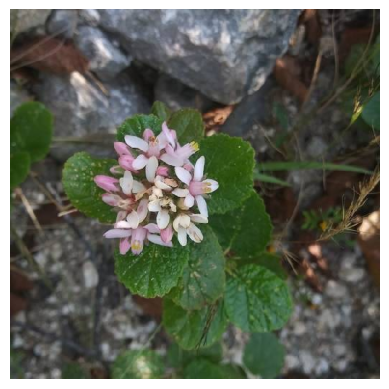

In [20]:
saple_img_path = '/kaggle/input/planttraits2024/train_images/100282707.jpeg'

img = mpimg.imread(saple_img_path)
plt.imshow(img)
plt.axis('off')
plt.show()

In [21]:
image_name = saple_img_path
image_files = [image_name]
images = load_images(image_files)
image_sizes = [x.size for x in images]
images_tensor = process_images(
    images,
    image_processor,
    model.config
).to(model.device, dtype=torch.float16)

input_ids = (
    tokenizer_image_token(prompt, tokenizer, IMAGE_TOKEN_INDEX, return_tensors="pt")
    .unsqueeze(0)
    .cuda()
)

In [22]:
temperature = 0.2
top_p = 0.7
num_beams = 1
max_new_tokens = 512

with torch.inference_mode():
    output_ids = model.generate(
        input_ids,
        images=images_tensor,
        image_sizes=image_sizes,
        do_sample=True if temperature > 0 else False,
        temperature=temperature,
        top_p=top_p,
        num_beams=num_beams,
        max_new_tokens=max_new_tokens,
        use_cache=True,
    )

outputs = tokenizer.batch_decode(output_ids, skip_special_tokens=True)[0].strip()
outputs = outputs.replace("<|end|>", "").strip()
#print(f"\n{outputs}\n")

In [23]:
outputs

'[0.22, 0.3, 0.61, 0.68]'

### Draw bbox in image

In [24]:
import cv2

def show_box(bbox, saple_img_path, color='red'):
    image = cv2.imread(f'{saple_img_path}')
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    xmin,ymin,width,height= bbox.split(",")

    xmin = int(float(xmin) * image.shape[1]) 
    ymin= int(float(ymin) * image.shape[0])  
    width = int(float(width) * image.shape[1]) 
    height= int(float(height) * image.shape[0]) 

    xmax = xmin + width
    ymax = ymin + height

    color_tuple = (255,0,0)
    if color == 'blue':
        color_tuple = (0,0,255)

    image = cv2.rectangle(image,(xmin,ymin), (xmax,ymax),color_tuple,3)

    img = Image.fromarray(image)
    return img

In [25]:
outputs = outputs.strip("[")
outputs = outputs.strip("]")
outputs

'0.22, 0.3, 0.61, 0.68'

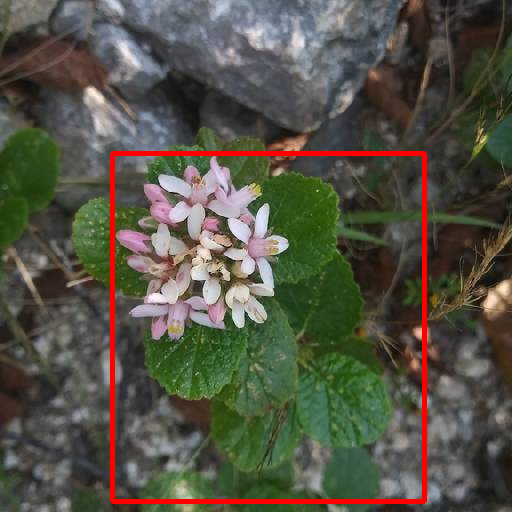

In [26]:
show_box(outputs, saple_img_path)

- model weight is here: https://www.kaggle.com/models/piantic/llava-phi-3-mini-4k-instruct